# What unhappy customers complain about

NMF topics on the **negative** reviews in the train sample (100,032), checked on the negative validation reviews. Uses the true labels, not the classifier's predictions, so the topics describe complaints, not the model's mistakes.

**First attempt:** NMF on all negative reviews found product types, not complaints. With 8 topics, four were simply books, films, music and games, because what people review differs more than what they complain about. So it runs in two stages (`reviews.topics.run`):

1. 8 topics on all negative reviews; reviews whose main topic is a media type are set aside.
2. Topics on the rest (about half: physical products, orders, service), where a product team could act on them.

In [1]:
import json
import os
from pathlib import Path

os.environ.setdefault("REVIEWS_DATA_DIR", "../data")

import matplotlib.pyplot as plt
import pandas as pd

from reviews import topics
from reviews.compare import load
from reviews.scrub import excerpt

saved = json.loads(Path("../reports/topics.json").read_text())
labels = pd.read_csv("../reports/topic_labels.csv")
pd.DataFrame({"stage 1 top words": [", ".join(w) for w in saved["stage1"]["top_words"]]})

,stage 1 top words
0,"work, use, bought, just, months, doesn"
1,"book, read, books, author, reading, story"
2,"movie, film, bad, watch, movies, acting"
3,"waste, money, waste money, don waste, don, was..."
4,"cd, album, songs, music, like, song"
5,"product, amazon, item, received, ordered, order"
6,"game, play, games, graphics, fun, played"
7,"quality, dvd, poor, poor quality, sound, video"


In [2]:
{k: v for k, v in saved["stage1"].items() if k != "top_words"}

{'k': 8,
 'media_topics': [1, 2, 4, 6],
 'goods_share_train': 0.499,
 'goods_share_validation': 0.496}

Topics 1, 2, 4 and 6 are books, films, music and games. About half of the negative reviews (49.9% in train, the same in validation) are left for stage 2.

## How many topics

In [3]:
pd.DataFrame(saved["stage2"]["choose_k"]).set_index("k")

,coherence,diversity
k,,
6,0.1775,0.983
8,0.1864,0.925
10,0.1844,0.910
12,0.1898,0.917
15,0.2033,0.900
20,0.1929,0.880


Coherence (mean NPMI of each topic's top 10 words, from how often they appear in the same review) peaks at 15 topics. It only moves between 0.18 and 0.20, so it's a tiebreak, not a verdict. Reading the topics settled it: at 10, battery problems, customer service and children's products were merged into broader topics; at 15 each is its own topic. At 20, most of the extra topics are the same complaint split by grammar ("doesn't work", "did not work", "does work" become three), though two useful ones appear: "doesn't look like the picture" and fit and size. Those two are folded into topic 0 and "doesn't work" at 15; a finer cut is a possible next step.

## The 15 topics, named by reading the reviews that load most on each

In [4]:
# The labels were written for this exact model: check its top words still match.
for row in labels.itertuples():
    expected = row.check_words.split("|")
    assert saved["stage2"]["top_words"][row.topic][:3] == expected, row.topic

table = labels[["topic", "label", "kind"]].assign(
    train=saved["stage2"]["share_train"],
    validation=saved["stage2"]["share_validation"],
    words=[", ".join(w[:6]) for w in saved["stage2"]["top_words"]],
)
table.sort_values("train", ascending=False)

,topic,label,kind,train,validation,words
0,0,"Too small, flimsy, not what was expected",complaint,0.107,0.106,"like, just, good, use, really, small"
3,3,Order never arrived or wrong item sent,complaint,0.107,0.110,"item, amazon, received, ordered, order, return"
9,9,"Poorly made, wouldn't recommend",verdict,0.093,0.093,"product, recommend, buy product, recommend pro..."
5,5,Stopped working after a few months,complaint,0.076,0.073,"months, working, stopped, worked, stopped work..."
4,4,Doesn't work at all,complaint,0.076,0.078,"work, does, did, does work, doesn, did work"
2,2,DVDs that won't play (region codes; players),complaint,0.069,0.067,"dvd, player, movie, play, dvd player, version"
6,6,Poor picture or sound quality,complaint,0.066,0.065,"quality, poor, poor quality, sound, sound qual..."
7,7,"""Don't buy""",verdict,0.064,0.058,"buy, don, don buy, know, don know, buy product"
1,1,"""Don't waste your money""",verdict,0.061,0.059,"waste money, waste, money, don waste, don, book"
12,12,Children's products and toys: size and age fit,complaint,0.056,0.055,"old, year, year old, toy, son, daughter"


- **11 are specific complaints**, 3 are verdicts with no subject ("don't buy", "waste of money", "wouldn't recommend") and 1 is book and film reviews that slipped past stage 1.
- **The shares hold on validation**: every topic is within 0.6 points of its training share, so these aren't artefacts of one sample.

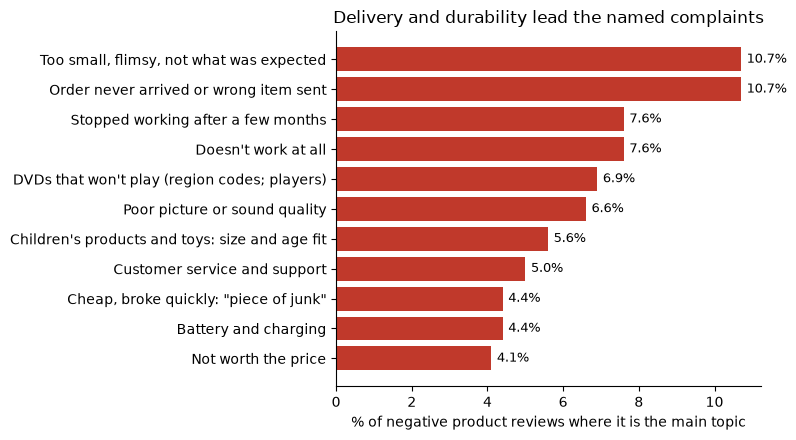

In [5]:
complaints = table[table["kind"] == "complaint"].sort_values("train")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(complaints["label"], complaints["train"] * 100, color="#c0392b")
for i, v in enumerate(complaints["train"] * 100):
    ax.text(v + 0.15, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlabel("% of negative product reviews where it is the main topic")
ax.set_title("Delivery and durability lead the named complaints")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("../reports/figures/complaint_topics.png", dpi=150)

## Examples (scrubbed, cut to 160 characters)

In [6]:
train_x, train_y = load("train")
val_x, val_y = load("validation")
neg_train = [t for t, y in zip(train_x, train_y, strict=True) if y == 0]
neg_val = [t for t, y in zip(val_x, val_y, strict=True) if y == 0]
fresh = topics.run(neg_train, neg_val)
assert fresh["stage2"]["top_words"] == saved["stage2"]["top_words"]
nmf, weights, goods = fresh["_fitted"]
for row in complaints.sort_values("train", ascending=False).itertuples():
    print(f"\n{row.label} ({row.train:.1%})")
    for text in topics.examples(weights, goods, row.topic, 2):
        print("  -", excerpt(text, 160))


Order never arrived or wrong item sent (10.7%)
  - sing me to sleep, Mommy. I ordered this item and paid for this item. I have never received. I have emailed the seller two times and have never received a…
  - Received wrong item. Received an item that was different that the one I ordered only to find out that what I had ordered was no longer available. They just…

Too small, flimsy, not what was expected (10.7%)
  - Bad Choice. Although its great to hold my new Dell DJ Ditty, It is way too small for my cellphone. Its too long, but not wide enough. Shipping was expensive,…
  - Even at $5 -- bad deal. I saw this thing and thought to myself, "$5? Sure I'll gamble that on something that might make scooping easier." I lost that bet.And I…

Doesn't work at all (7.6%)
  - volume does not work. volume does not work will not play properly.tried several players and did not work on any of them.have to blast tv just to get little…
  - does not work. bought a similiar product, does not work, stil

## Takeaways

1. **Delivery ties for the top spot**: orders that never arrived or the wrong item (10.7% of negative product reviews), plus customer service (5%). That's the seller and the shop, not the product, so a product team alone can't fix it. The other 10.7% topic is broad (too small, flimsy, not as expected) and would need a finer cut.
2. **Durability comes next**: stopped working after months (8%), cheap and broke quickly (4%), battery and charging (4%).
3. **Doesn't work at all** (8%) and **DVDs that won't play** (7%, mostly region codes and player compatibility) are about compatibility as much as quality.
4. **Children's products** get their own topic (6%): size and age ranges that don't match the description.
5. About a fifth of negative product reviews are mainly a verdict ("don't buy", "waste of money") with no complaint NMF can name.

Limits: one topic per review (its main one), English, Amazon before about 2014, and no product category or date in the data, so topics can't be split by department or followed over time.